In [1]:
print('In the name of Allah')

In the name of Allah


In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import numpy as np

# Loading the dataset

In [3]:
train_images = np.load('/content/train_images.npy')
train_labels = np.load('/content/train_labels.npy')
test_images = np.load('/content/test_images.npy')
test_labels = np.load('/content/test_labels.npy')

In [4]:
print(f'Shape of Train Images : {train_images.shape}')
print(f'Shape of Test Images : {test_images.shape}')

Shape of Train Images : (60000, 28, 28)
Shape of Test Images : (10000, 28, 28)


In [5]:
train_labels.shape

(60000,)

In [6]:
train_images[0]

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,
         18,  18,  18, 126, 136, 175,  26, 166, 255, 247, 127,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,  30,  36,  94, 154, 170,
        253, 253, 253, 253, 253, 225, 172, 253, 242, 195,  64,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,  49, 238, 253, 253, 253, 253,
        253, 253, 253, 253, 251,  93,  82,  82,  56,  39,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,  18, 219, 253, 253, 253, 253,
        253, 198, 182, 247, 241,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,  80, 156, 107, 253, 253,
        205,  11,   0,  43, 154,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,  14,   1, 154, 253,
         90,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0, 139, 253,
        190,   2,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  11, 190,
        253,  70,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  35,
        241, 225, 160, 108,   1,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         81, 240, 253, 253, 119,  25,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,  45, 186, 253, 253, 150,  27,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,  16,  93, 252, 253, 187,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0, 249, 253, 249,  64,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,  46, 130, 183, 253, 253, 207,   2,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  39,
        148, 229, 253, 253, 253, 250, 182,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  24, 114, 221,
        253, 253, 253, 253, 201,  78,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,  23,  66, 213, 253, 253,
        253, 253, 198,  81,   2,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,  18, 171, 219, 253, 253, 253, 253,
        195,  80,   9,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,  55, 172, 226, 253, 253, 253, 253, 244, 133,
         11,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0, 136, 253, 25

In [7]:
train_labels[0]

np.uint8(5)

In [8]:
# tansordataset example

features = torch.tensor( [[1.0, 2.0], [3.0, 4.0], [5.0, 6.0]] )
labels = torch.tensor( [0, 1, 0] )

dataset = TensorDataset( features, labels )

dataset[0]

(tensor([1., 2.]), tensor(0))

In [9]:
# dataloader

dataloader = DataLoader( dataset, batch_size = 2, shuffle = True )

for batch in dataloader :
  features, label = batch
  print('Feature : ', features)
  print('Label : ', label)

Feature :  tensor([[1., 2.],
        [5., 6.]])
Label :  tensor([0, 0])
Feature :  tensor([[3., 4.]])
Label :  tensor([1])


Text(0.5, 1.0, 'Label : 5')

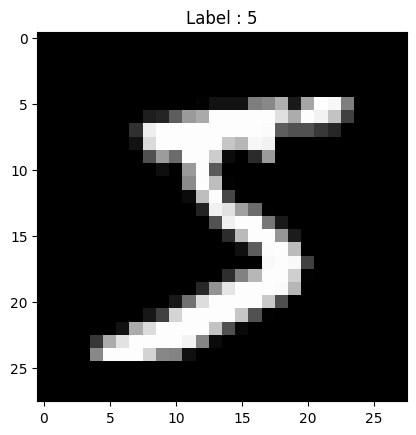

In [10]:
import matplotlib.pyplot as plt

plt.imshow( train_images[0], cmap = 'gray' )
plt.title( f'Label : {train_labels[0]}' )

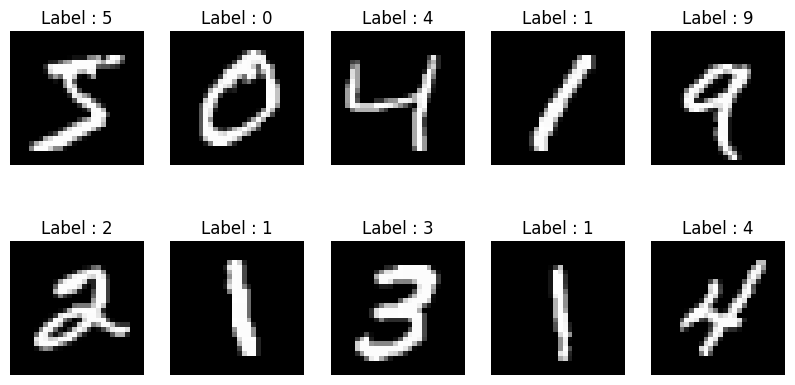

In [11]:
fig, axes = plt.subplots( 2, 5, figsize = ( 10, 5 ) )

axes = axes.flatten()

for i in range( 10 ) :
  axes[i].imshow( train_images[i], cmap = 'gray' )
  axes[i].set_title( f'Label : {train_labels[i]}' )
  axes[i].axis('off')

plt.show()

In [12]:
from sklearn.model_selection import train_test_split

X_train_np, X_val_np, y_train_np, y_val_np = train_test_split( train_images, train_labels, test_size = 0.10, random_state = 42 )


In [13]:
X_train = torch.tensor( X_train_np, dtype = torch.float32 )
y_train = torch.tensor( y_train_np, dtype = torch.long )
X_val = torch.tensor( X_val_np, dtype = torch.float32 )
y_val = torch.tensor( y_val_np, dtype = torch.long )

X_test = torch.tensor( test_images, dtype = torch.float32 )
y_test = torch.tensor( test_labels, dtype = torch.long )

In [14]:
train_dataset = TensorDataset( X_train, y_train )
val_dataset = TensorDataset( X_val, y_val )
test_dataset = TensorDataset( X_test, y_test )


In [15]:
X_train.shape

torch.Size([54000, 28, 28])

In [16]:
train_loader = DataLoader( train_dataset, batch_size = 64, shuffle = True )
val_loader = DataLoader( val_dataset, batch_size = 64, shuffle = True )
test_loader = DataLoader( test_dataset, batch_size = 64, shuffle = True )

In [17]:
class DigitClassificationModel( nn.Module ) :

  def __init__( self, input_size, num_classes ) :

    super().__init__()

    self.network = nn.Sequential(
        nn.Flatten(),
        nn.Linear(input_size, 128), # 128 layer = 128 ta neuron
        nn.ReLU(),
        nn.Linear(128, 64), # 2nd layer e 64 ta neuron
        nn.ReLU(),
        nn.Linear(64, num_classes) # Output layer
     )

  def forward( self, features ) :
    output = self.network(features)
    return output



In [18]:
model = DigitClassificationModel( input_size = 28 * 28, num_classes = 10 )

In [19]:
print(model)

DigitClassificationModel(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Linear(in_features=64, out_features=10, bias=True)
  )
)


In [20]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()

optimizer = optim.SGD( model.parameters(), lr = 0.01 )


In [21]:
epochs = 10


for epoch in range( epochs ) :

  running_loss = 0.0

  for images, labels in train_loader :
    optimizer.zero_grad()

    outputs = model( images )

    loss = criterion( outputs, labels )

    loss.backward()

    optimizer.step()

    running_loss += loss.item()

  val_loss = 0.0

  with torch.no_grad() :
    for images, labels in val_loader :
      outputs = model(images)
      loss = criterion( outputs, labels )
      val_loss += loss.item()

  print(f'Epoch : {epoch + 1} / {epochs} | Train  Loss : {running_loss:.4f} | Validation loss : {val_loss:.4f}')

Epoch : 1 / 10 | Train  Loss : 3633.5028 | Validation loss : 190.2728
Epoch : 2 / 10 | Train  Loss : 1659.8734 | Validation loss : 198.1596
Epoch : 3 / 10 | Train  Loss : 1583.9257 | Validation loss : 155.8336
Epoch : 4 / 10 | Train  Loss : 1210.0830 | Validation loss : 122.1598
Epoch : 5 / 10 | Train  Loss : 1660.0827 | Validation loss : 179.5613
Epoch : 6 / 10 | Train  Loss : 1669.3765 | Validation loss : 173.7773
Epoch : 7 / 10 | Train  Loss : 1513.2575 | Validation loss : 162.7812
Epoch : 8 / 10 | Train  Loss : 1592.6378 | Validation loss : 197.2206
Epoch : 9 / 10 | Train  Loss : 1526.4118 | Validation loss : 184.0971
Epoch : 10 / 10 | Train  Loss : 1636.8950 | Validation loss : 166.1708


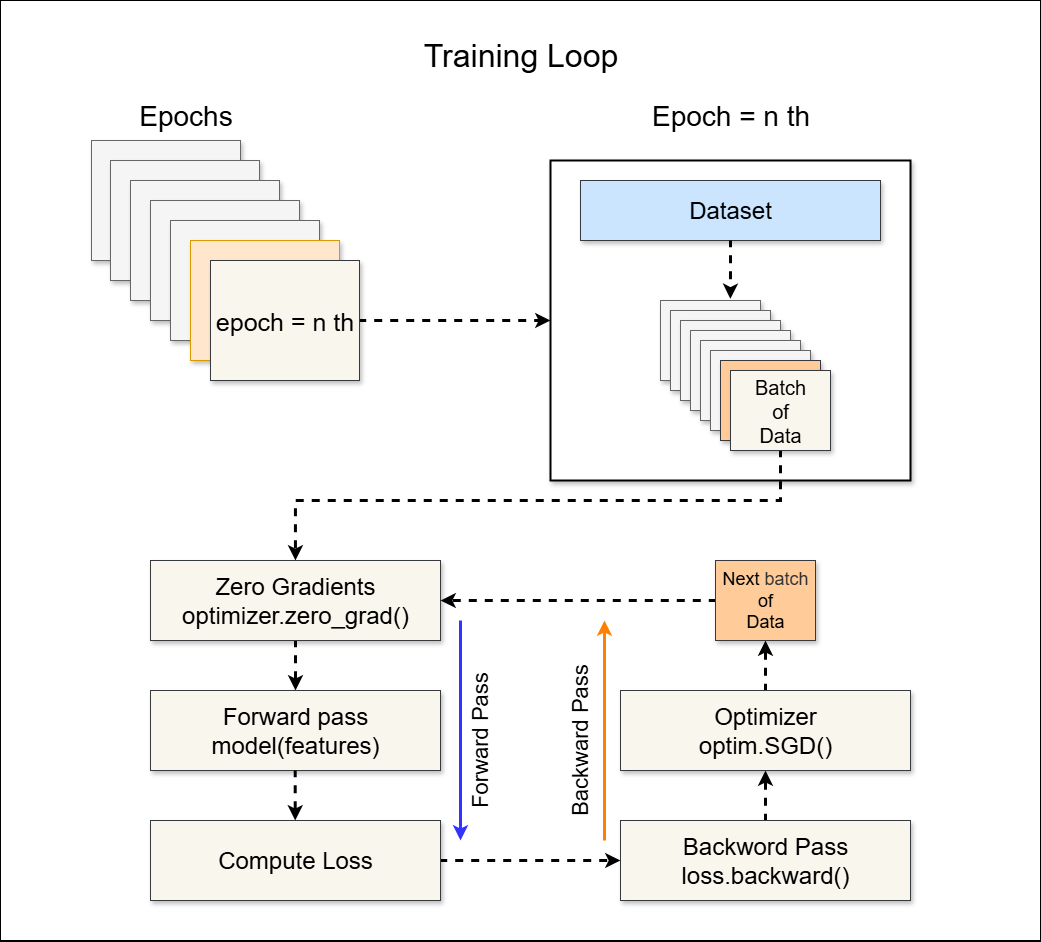

In [22]:
with torch.no_grad():
  y_pred_prob = model(X_test)


y_pred_prob.shape

y_pred = torch.argmax( y_pred_prob, dim = 1 )

print("Predication : ", y_pred[:10])
print("Actual : ", y_test[:10])

Predication :  tensor([7, 6, 7, 0, 7, 7, 7, 7, 6, 7])
Actual :  tensor([7, 2, 1, 0, 4, 1, 4, 9, 5, 9])


# Accuracy Report, Confusion Matrix

In [23]:
from sklearn.metrics import accuracy_score, confusion_matrix
import seaborn as sns

# Calculate Accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy:.4f}')

Accuracy: 0.2870


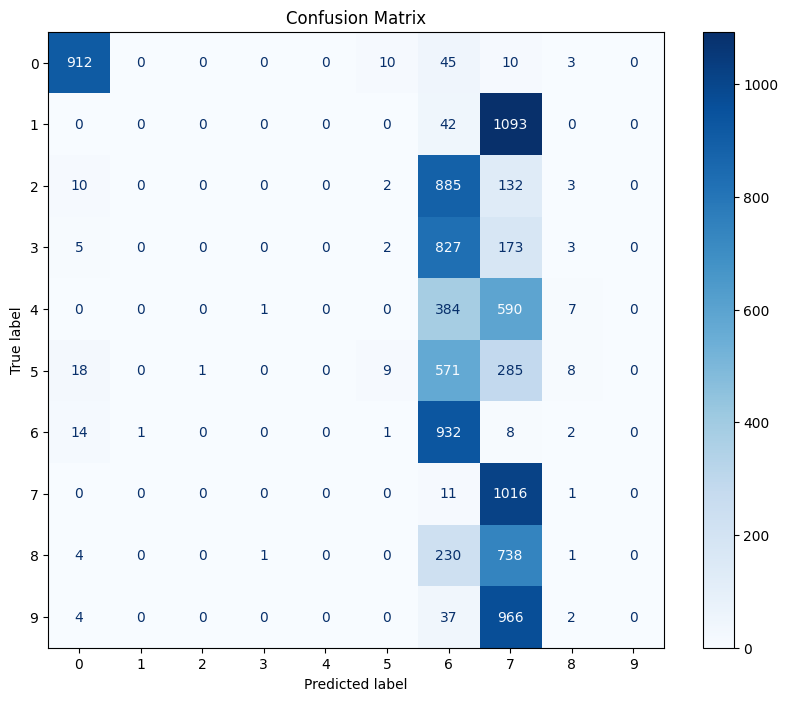

In [24]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Define class names for MNIST (digits 0-9)
class_names = [str(i) for i in range(10)]

# Get the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Plot the confusion matrix using ConfusionMatrixDisplay
fig, ax = plt.subplots(figsize=(10, 8))
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

plt.title("Confusion Matrix")
display.plot(ax=ax, cmap=plt.cm.Blues)
plt.show()